# 30 · Phase 3: live paired cameras

Phase 3 runs CFFM-Net with its memory on live streams. Each camera has its own capture thread and a one-frame queue, so the model always sees the present. A stream monitor watches arrival times and pixels and raises the sensor flags, and the real time between frames sets the memory's step. Recorded KAIST test sequences are replayed in real time as cameras, so every run is repeatable; the same runtime takes webcams and RTSP URLs through `stream.DeviceSource`.

| | |
|---|---|
| **Kaggle settings** | Accelerator **GPU T4 x2**, Internet **on** |
| **Inputs to attach** | `cffm-net-pilot`, KAIST frames and annotations, and the output of notebook 20 |
| **Expected runtime** | about 40 minutes on one T4 |
| **Produces** | `results/phase3/`: soak and fault tables, latency plot, a recorded live session |

In [1]:
import glob, shutil, subprocess, sys
from pathlib import Path

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    PROJECT = Path("/kaggle/working/cffm-net-pilot")
    if not PROJECT.exists():
        hits = [Path(p).parent for k in range(1, 6) for p in glob.glob("/kaggle/input" + "/*" * k + "/pyproject.toml")
                if (Path(p).parent / "src" / "cffm").is_dir()]
        hits.sort(key=lambda h: any((h.parent / d).exists() for d in ("runs", "data")))
        zips = [Path(p) for k in range(1, 5) for p in glob.glob("/kaggle/input" + "/*" * k + ".zip")
                if "cffm" in Path(p).name]
        if hits:
            shutil.copytree(hits[0], PROJECT, copy_function=shutil.copyfile)
        elif zips:
            shutil.unpack_archive(str(zips[0]), "/kaggle/working")
        assert PROJECT.exists(), "Add the 'cffm-net-pilot' dataset (the uploaded zip) as an input to this notebook."
        for p in [PROJECT, *PROJECT.rglob("*")]:
            p.chmod(p.stat().st_mode | 0o200)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.171",
                    "faster-coco-eval>=1.6.7", "cloudpickle", "pytest", "lap>=0.5.12", "imageio-ffmpeg", "motmetrics"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "-e", str(PROJECT)], check=True)
else:
    PROJECT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src" / "cffm").is_dir())
sys.path.insert(0, str(PROJECT / "src"))

import cffm
from cffm import env as cenv, pipeline
print("cffm", cffm.__version__, "imported from", Path(cffm.__file__).parent)
env = cenv.setup()
plan = pipeline.load_plan(env.project)

cffm 0.1.0 imported from C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\src\cffm


platform=local  device=0  gpus=[NVIDIA GeForce RTX 4050 Laptop GPU (6 GB)]  scan=torch
project=C:\Users\roshh\Desktop\computer vision\cffm-net-pilot
data=C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\data\processed
runs=C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\runs


In [2]:
from pathlib import Path
import json, shutil, time
import cv2, numpy as np, pandas as pd, torch
from cffm import kaist, video, faults, hud, showcase as sc
from cffm.train import _load

INPUT = [Path("/kaggle/input")] if ON_KAGGLE else [env.project / "data" / "raw"]
IMG_ROOT, ANN_ROOT = kaist.find_roots(INPUT)
dev = "cuda:0" if torch.cuda.is_available() else "cpu"
out = env.project / "results" / "phase3"
out.mkdir(parents=True, exist_ok=True)
for f in Path("/kaggle/input").glob("**/results/phase3/*"):
    if f.suffix in (".json", ".pt") and not (out / f.name).exists():
        shutil.copy(f, out / f.name)
print("KAIST images:", IMG_ROOT, "| annotations:", ANN_ROOT, "| device:", dev)

from cffm import stream
ckpts = pipeline.find_checkpoints(env)
name = "kaist_cffm_v2" if "kaist_cffm_v2" in ckpts else "llvip_cffm_v2_e80"
model = _load(ckpts[name]).to(dev).eval()
model.attach_memory()
mem = next(iter(sorted(Path("/kaggle/input" if ON_KAGGLE else env.project).glob("**/results/phase2/memory.pt"))), None)
if mem is not None:
    model.memory.load_state_dict(torch.load(mem, map_location=dev))
print("model:", name, "| memory:", mem or "untrained (identity)")
test_seqs = kaist.sequences(IMG_ROOT, ANN_ROOT, kaist.TEST_SETS)
frames = [f for s in test_seqs for f in s.frames]
irs = [kaist.lwir(f) for f in frames]
gt = {i: b for i, b in enumerate(b for s in test_seqs for b in s.boxes)}

def cameras(fps, vis_faults=None, ir_faults=None):
    t0 = time.perf_counter() + 1.0
    v = stream.Camera("visible", lambda: stream.ReplaySource(frames, fps=fps, t0=t0, faults=vis_faults))
    i = stream.Camera("thermal", lambda: stream.ReplaySource(irs, fps=fps, grey=True, t0=t0, faults=ir_faults),
                      grey=True)
    return v, i, t0

KAIST images: C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\data\raw\kaist\extracted\kaist-cvpr15\images | annotations: C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\data\raw\kaist_ann\annotations | device: cuda:0


C:\Users\roshh\Desktop\computer vision\.venv\Lib\site-packages\triton\knobs.py:524: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


model: kaist_cffm_v2 | memory: C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\results\phase2\memory.pt


## 1. Soak test

The exit test: paired 640 x 512 cameras at 30 fps for ten minutes, with no growth in delay or memory. Frames the model cannot keep up with are dropped at capture, never queued.

,seconds,fps,e2e_p50,e2e_p95,infer_p50,infer_p95,drift_ms,gpu_growth_mb,capture_drop_rate
30 fps,594.07,12.40,94.42,117.86,70.86,88.69,0.33,-1.0,0.59
20 fps,116.92,12.69,99.99,129.86,68.31,89.35,8.16,0.0,0.36


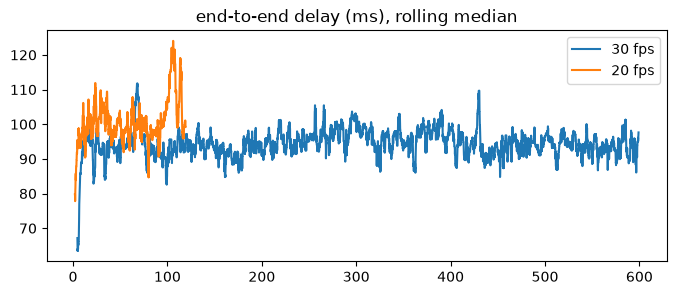

In [3]:
cache = out / "soak.json"
if cache.exists():
    soak = json.loads(cache.read_text())
else:
    soak = {}
    for fps, secs in ((30, 600), (20, 120)):
        v, i, t0 = cameras(fps)
        rt = stream.Runtime(model, v, i, fps=fps, device=dev)
        rec = rt.run(secs)
        rt.close()
        s = stream.summary(rec)
        s["capture_drop_rate"] = v.q.dropped / max(v.q.put_count, 1)
        soak[f"{fps} fps"] = s
        e2e = pd.Series([r["e2e_ms"] for r in rec], index=[r["t"] - t0 for r in rec])
        e2e.rolling(30).median().plot(figsize=(8, 3), label=f"{fps} fps", legend=True,
                                      title="end-to-end delay (ms), rolling median")
    cache.write_text(json.dumps(soak, indent=2))
pd.DataFrame(soak).T.round(2)

## 2. Faults on the link

Nearly two minutes at 20 fps with a scripted sequence of failures: the thermal cable pulled for 6 s, the visible camera frozen for 6 s, the thermal stream stalled for 3 s, 10 % random drops and 60 ms of extra delay on thermal. The monitor must flag each fault quickly, clear it when the camera returns, and raise no false alarms. The same run without the monitor shows what the flags are worth.

In [4]:
cache = out / "faults.json"
SCRIPT = {"thermal unplugged": ("ir", 20, 26), "visible frozen": ("vis", 50, 56), "thermal stalled": ("ir", 80, 83)}
if cache.exists():
    fres = json.loads(cache.read_text())
else:
    fres = {}
    for monitor in (True, False):
        ir_f = stream.StreamFaults(unplugs=[(20, 26)], stalls=[(80, 83)], drop_p=0.1, delay_s=0.06)
        vis_f = stream.StreamFaults(freezes=[(50, 56)], drop_p=0.1)
        v, i, t0 = cameras(20, vis_f, ir_f)
        rt = stream.Runtime(model, v, i, fps=20, device=dev, use_monitor=monitor)
        rec = rt.run(110)
        rt.close()
        dets = [r["dets"] for r in rec if r["vis_idx"] >= 0]
        boxes = [gt[r["vis_idx"] % len(frames)] for r in rec if r["vis_idx"] >= 0]
        fres["monitor on" if monitor else "monitor off"] = {
            "summary": stream.summary(rec), "reconnects": i.reconnects, "MR_all": kaist.miss_rate(dets, boxes),
            "faults": {k: stream.detection_delay(rec, a, b, camera=c, start=t0) for k, (c, a, b) in SCRIPT.items()}}
    cache.write_text(json.dumps(fres, indent=2, default=float))
pd.DataFrame(fres["monitor on"]["faults"]).T.round(3)

,detect_s,recover_s,false_alarm_rate
thermal unplugged,0.291,0.195,0.043
visible frozen,0.691,0.104,0.000
thermal stalled,0.314,0.125,0.061


In [5]:
pd.DataFrame({k: {"miss rate (%)": v["MR_all"] * 100, "fps": v["summary"]["fps"],
                  "e2e p95 (ms)": v["summary"]["e2e_p95"], "camera reconnects": v["reconnects"]}
              for k, v in fres.items()}).T.round(2)

,miss rate (%),fps,e2e p95 (ms),camera reconnects
monitor on,27.87,11.79,139.44,10.0
monitor off,27.09,12.01,139.44,10.0


## 3. The live board

Forty seconds of the live system as the operator sees it: both cameras, every subject tracked and numbered, the health of each link and the delay of each frame. The thermal cable is pulled at 15 s and plugged back at 21 s.

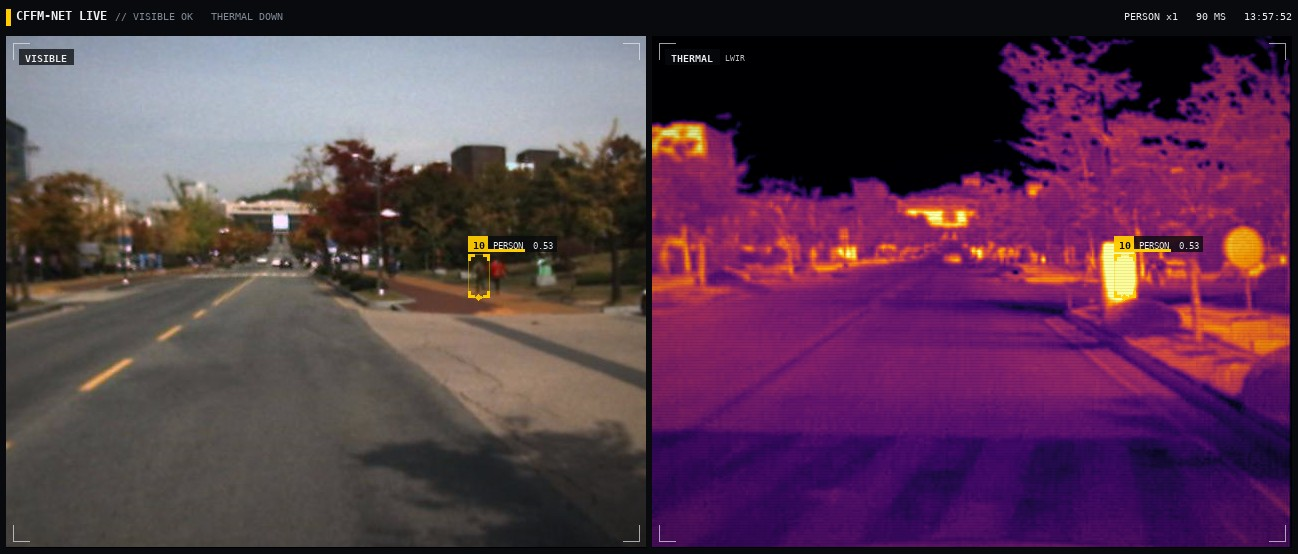

In [6]:
boards = []

def draw(vis, ir, rec):
    if len(boards) >= 800 or vis is None or ir is None:
        return
    img = np.concatenate([vis.image, cv2.resize(ir.image, vis.image.shape[1::-1])[..., None]], 2)
    tr = np.asarray(rec["tracks"]).reshape(-1, 8) if len(rec["tracks"]) else np.zeros((0, 8))
    det = np.column_stack([tr[:, :4], tr[:, 5], tr[:, 6]]) if len(tr) else np.zeros((0, 6))
    status = f"VISIBLE {rec['vis'].upper()}   THERMAL {rec['ir'].upper()}"
    boards.append(hud.render(img, det, {0: "person"}, ids=tr[:, 4].astype(int).tolist() if len(tr) else None,
                             latency_ms=rec["e2e_ms"], panel_w=640, title="CFFM-NET LIVE", subtitle=status,
                             panels=("visible", "thermal")))

v, i, t0 = cameras(20, ir_faults=stream.StreamFaults(unplugs=[(15, 21)]))
rt = stream.Runtime(model, v, i, fps=20, device=dev, render=draw, conf=0.3)
rt.run(40)
rt.close()
hud.save_video(boards, out / "live_session.mp4", fps=20, width=1280)
sc.show(boards[len(boards) // 2])

In [7]:
(out / "phase3_summary.json").write_text(json.dumps({"soak": soak, "faults": fres}, indent=2, default=float))
print("saved", sorted(p.name for p in out.iterdir()))

saved ['faults.json', 'live_session.mp4', 'phase3_summary.json', 'soak.json']
